In [3]:
import sys
# from opentrons import protocol_api, execute, simulate
# from opentrons.types import Location, Point
import pandas as pd
import numpy as np
import random
import requests
import ast  # safer than eval
from pyDOE import lhs
import random
import matplotlib.pyplot as plt

import os
import cv2
import json
import seaborn as sns

import asyncio
import websockets
import base64
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as IPythonImage
from ipywidgets import interact, IntSlider, fixed
from IPython.display import display, HTML
from color_mixing import GaussianProcess, BayesianOptimization

On raspberry pi terminal, run:
```
python3 websocket_server.py
```

To focus the camera, Open a new terminal and enter:
```
libcamera-still -t 0 --autofocus-mode manual --lens-position 5 --tuning-file /usr/share/libcamera/ipa/vc4/imx219_af.json
```

In [4]:
image_path = f"images/9.jpg"
# parameters for bilateral filtering
diameter = 5
sigmaColor = 75
sigmaSpace = 75

image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

rows = 8
cols = 12

top_left = (250, 250)
bottom_right = (3000, 2000)
# Add sliders to control the top-left and bottom-right positions
top_left_x = IntSlider(value=top_left[0], min=0, max=image_rgb.shape[1], description="Top Left X")
top_left_y = IntSlider(value=top_left[1], min=0, max=image_rgb.shape[0], description="Top Left Y")
bottom_right_x = IntSlider(value=bottom_right[0], min=0, max=image_rgb.shape[1], description="Bottom Right X")
bottom_right_y = IntSlider(value=bottom_right[1], min=0, max=image_rgb.shape[0], description="Bottom Right Y")

@interact(top_left_x=top_left_x, top_left_y=top_left_y, bottom_right_x=bottom_right_x, bottom_right_y=bottom_right_y)
def update_grid(top_left_x, top_left_y, bottom_right_x, bottom_right_y):
    # Update coordinates for top-left and bottom-right grid points
    top_left = (top_left_x, top_left_y)
    bottom_right = (bottom_right_x, bottom_right_y)

    x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
    y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

    expected_grid = []
    rgb_values = []

    for row in range(rows):
        for col in range(cols):
            x = int(top_left[0] + col * x_step)
            y = int(top_left[1] + row * y_step)
            expected_grid.append((x, y))

            # image[row, col] → image[y, x]
            b, g, r = image_rgb[y, x]
            rgb_values.append([r, g, b])

    output_grid = image_rgb.copy()

    # Draw circles
    for (x, y) in expected_grid:
        cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

    output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(output_grid_rgb)
    plt.axis("off")
    plt.title("Contour Detection")
    plt.show()


interactive(children=(IntSlider(value=250, description='Top Left X', max=3280), IntSlider(value=250, descripti…

background subtration

In [5]:
def image_rgb_extraction(image_path):
    # parameters for bilateral filtering
    diameter = 5
    sigmaColor = 75
    sigmaSpace = 75

    image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
    image_rgb = cv2.imread(image_path)

    rows = 8
    cols = 12

    # define coordinates for top-left and bottom-right grid points
    top_left = (top_left_x.value, top_left_y.value)
    bottom_right = (bottom_right_x.value, bottom_right_y.value)

    x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
    y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

    expected_grid = []
    new_rgb_values = []

    for row in range(rows):
        for col in range(cols):
            x = int(top_left[0] + col * x_step)
            y = int(top_left[1] + row * y_step)
            expected_grid.append((x, y))
            
            # image[row, col] → image[y, x]
            b, g, r = image_rgb[y, x]  
            new_rgb_values.append([r, g, b]) 

    output_grid = image_rgb.copy()

    # draw circle
    for (x, y) in expected_grid:
        cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

    output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(output_grid_rgb)
    plt.axis("off")
    plt.title("Contour Detection")
    plt.show()

    return new_rgb_values

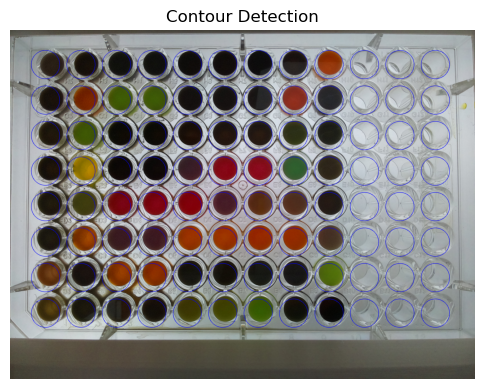

1st well: [56, 41, 12]
2nd well: [91, 47, 12]


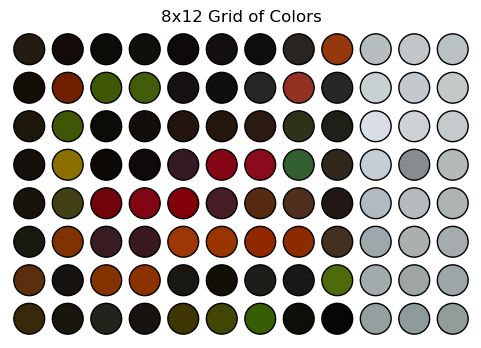

In [6]:
counter = 9
rgb_values = image_rgb_extraction(f"images/{counter}.jpg")
# Display the RGB values in a grid
fig, ax = plt.subplots(figsize=(6, 4))
# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)

print('1st well:', rgb_values[84])
print('2nd well:', rgb_values[72])

ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()


In [14]:
import numpy as np
import colour
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, get_cmap
from skimage import color
from colour import MSDS_CMFS, colorimetry, XYZ_to_sRGB, XYZ_to_xy
from skimage.color import xyz2rgb as color_xyz2rgb  # Use skimage's version here
from matplotlib.path import Path

def load_cie_1931_cmf():
    """Returns standard CIE 1931 CMFs: wavelengths (nm), x̄, ȳ, z̄"""
    # Load the CIE 1931 2-degree color matching functions
    cmfs = colour.MSDS_CMFS['cie_2_1931']

    # Access the data as a NumPy array
    wavelengths = cmfs.wavelengths
    x_bar = cmfs.values[:, 0]
    y_bar = cmfs.values[:, 1]
    z_bar = cmfs.values[:, 2]
    return wavelengths, x_bar, y_bar, z_bar

def rgb_to_xy(rgb):
    """
    Convert RGB values to CIE 1931 x, y chromaticity coordinates.

    Parameters:
    - rgb: numpy array of shape (..., 3) with RGB values in the range [0, 1]

    Returns:
    - x, y: chromaticity coordinates
    """
    # Define the RGB to XYZ transformation matrix (sRGB D65 standard)
    rgb_to_xyz_matrix = np.array([
        [0.4124564, 0.3575761, 0.1804375],
        [0.2126729, 0.7151522, 0.0721750],
        [0.0193339, 0.1191920, 0.9503041]
    ])

    # Ensure RGB is in the correct shape
    rgb = np.asarray(rgb)
    if rgb.ndim == 1:
        rgb = rgb[np.newaxis, :]  # Add batch dimension if needed

    # Convert RGB to XYZ
    XYZ = np.dot(rgb, rgb_to_xyz_matrix.T)

    # Normalize to get chromaticity coordinates
    X, Y, Z = XYZ[..., 0], XYZ[..., 1], XYZ[..., 2]
    total = X + Y + Z
    x = np.divide(X, total, out=np.zeros_like(X), where=total != 0)
    y = np.divide(Y, total, out=np.zeros_like(Y), where=total != 0)

    return x, y

def get_spectral_locus_path():
    """Return spectral locus as a Path object for masking."""
    lam, x_bar, y_bar, z_bar = load_cie_1931_cmf()
    XYZ = np.stack([x_bar, y_bar, z_bar], axis=1)
    XYZ_sum = np.sum(XYZ, axis=1, keepdims=True)
    xy = XYZ / XYZ_sum
    return Path(xy[:, :2])  # convert to Path

def plot_chromaticity_diagram():
    lam, x_bar, y_bar, z_bar = load_cie_1931_cmf()
    
    # Normalize to chromaticity
    XYZ = np.stack([x_bar, y_bar, z_bar], axis=1)
    XYZ_sum = np.sum(XYZ, axis=1, keepdims=True)
    chromaticity = XYZ / XYZ_sum

    # plt.figure(figsize=(8, 8))
    plt.plot(chromaticity[:, 0], chromaticity[:, 1], 'k-', label='Spectral Locus') # This the the horse shoe shape
    # plt.fill(chromaticity[:, 0], chromaticity[:, 1], color='lightgray', alpha=0.5)
    
    # sRGB triangle
    sRGB_xy = np.array([
        [0.64, 0.33],  # R
        [0.30, 0.60],  # G
        [0.15, 0.06],  # B
        [0.64, 0.33]   # Close
    ])
    plt.plot(sRGB_xy[:, 0], sRGB_xy[:, 1], 'k--', label='sRGB gamut') # This is the triangle

    plt.title('CIE 1931 Chromaticity Diagram')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.axis([0, 0.8, 0, 0.9])
    plt.grid(True)
    # plt.legend()


def xy_to_XYZ(x, y, Y=1.0):
    """Convert (x, y) chromaticity to XYZ color with luminance Y."""
    X = (x * Y) / y
    Z = ((1 - x - y) * Y) / y
    return np.stack([X, Y * np.ones_like(x), Z], axis=-1)

def generate_cie_1931_background(res=0.001):
    """Generate RGB-filled CIE 1931 background image in x-y space."""
    x = np.arange(0, 0.8, res)
    y = np.arange(0, 0.9, res)
    xx, yy = np.meshgrid(x, y)
    mask = (xx + yy) <= 1  # only keep valid chromaticity points

    # Convert (x, y) → XYZ
    XYZ = xy_to_XYZ(xx, yy)
    XYZ[~mask] = 0

    # Convert XYZ to RGB
    RGB = color.xyz2rgb(XYZ)

    # # Constrain RGB values to valid range
    RGB[RGB < 0] = 0
    RGB[RGB > 1] = 1
    RGB[~mask] = 1  # White background outside valid gamut

    return xx, yy, RGB




File: 0, Chromaticity coordinates (x, y): ([ 0.36023693], [ 0.36690434])
File: 1, Chromaticity coordinates (x, y): ([ 0.37255435], [ 0.35469151])
File: 2, Chromaticity coordinates (x, y): ([ 0.33609871], [ 0.37825728])
File: 3, Chromaticity coordinates (x, y): ([ 0.33672097], [ 0.36028842])
File: 4, Chromaticity coordinates (x, y): ([ 0.34544541], [ 0.33928919])
File: 5, Chromaticity coordinates (x, y): ([ 0.33485843], [ 0.33596736])
File: 6, Chromaticity coordinates (x, y): ([ 0.3127266], [ 0.32902315])
File: 7, Chromaticity coordinates (x, y): ([ 0.32976863], [ 0.34105739])
File: 8, Chromaticity coordinates (x, y): ([ 0.47202003], [ 0.40970537])
File: 9, Chromaticity coordinates (x, y): ([ 0.30987035], [ 0.32732872])
File: 10, Chromaticity coordinates (x, y): ([ 0.30968111], [ 0.32687257])
File: 11, Chromaticity coordinates (x, y): ([ 0.30883871], [ 0.3273551])
File: 12, Chromaticity coordinates (x, y): ([ 0.37548916], [ 0.38378264])
File: 13, Chromaticity coordinates (x, y): ([ 0.52

/var/folders/w5/97kpzvwd275ccm0x7kqfrby00000gn/T/ipykernel_98581/4291266404.py:94: RuntimeWarning: divide by zero encountered in divide
  X = (x * Y) / y
/var/folders/w5/97kpzvwd275ccm0x7kqfrby00000gn/T/ipykernel_98581/4291266404.py:94: RuntimeWarning: invalid value encountered in divide
  X = (x * Y) / y
/var/folders/w5/97kpzvwd275ccm0x7kqfrby00000gn/T/ipykernel_98581/4291266404.py:95: RuntimeWarning: divide by zero encountered in divide
  Z = ((1 - x - y) * Y) / y


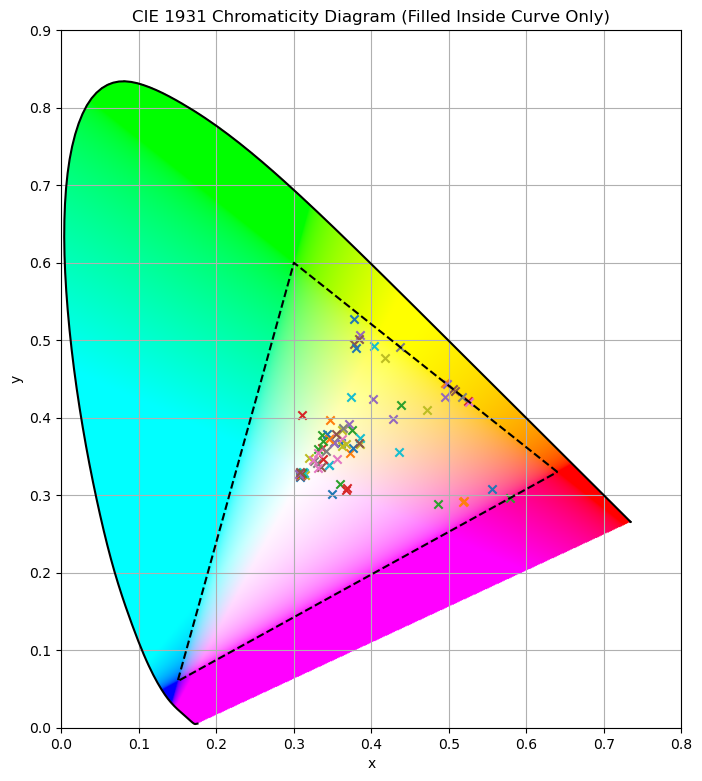

In [15]:
# Extract x, y chromaticity coordinates for all files
chromaticity_coordinates = {}

for i in range(len(rgb_values)):
    x, y = rgb_to_xy(rgb_values[i])
    chromaticity_coordinates[i] = (x, y)

# Display the results
for file, (x, y) in chromaticity_coordinates.items():
    print(f"File: {file}, Chromaticity coordinates (x, y): ({x}, {y})")

# Plot the x, y chromaticity coordinates
plt.figure(figsize=(8, 10))
for file, (x, y) in chromaticity_coordinates.items():
    plt.scatter(x, y, marker='x',label=file)

    # # Overlay the sRGB primaries closed polygon
    # sRGB_polygon = plt.Polygon(sRGB_primaries_closed, color='grey', alpha=0.01, label='sRGB Gamut')
    # plt.gca().add_patch(sRGB_polygon)
plot_chromaticity_diagram()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Chromaticity Coordinates (x, y)')
# plt.legend(loc='upper right', bbox_to_anchor=(1.5, 1))
plt.grid(True)

# Generate background
xx, yy, RGB = generate_cie_1931_background()


# Mask the RGB values outside the spectral locus
spectral_path = get_spectral_locus_path()
xy_points = np.stack([xx.ravel(), yy.ravel()], axis=-1)
inside_mask = spectral_path.contains_points(xy_points).reshape(xx.shape)

# Set RGB values outside the spectral locus to white
RGB[~inside_mask] = 1.0

# Plot the chromaticity diagram with the masked RGB background
plt.imshow(RGB, extent=(0., 0.8, 0, 0.9), origin='lower')
plt.title("CIE 1931 Chromaticity Diagram (Filled Inside Curve Only)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.xlim(0, 0.8)
plt.ylim(0, 0.9)
plt.show()


In [ ]:
def objective(rgb_list):
    # target_rgb = np.array([252, 186, 3])  # Example target RGB
    target_rgb = np.array([48, 145, 51])  # Convert to BGR
    rgb_list = np.array(rgb_list)
    return np.linalg.norm(rgb_list - target_rgb, axis=1)


In [17]:
min_id = np.argmin(objective(rgb_values))
print("Minimum ID:", min_id)

Minimum ID: 43


# Start of Color Iterations!


In [13]:
import torch
# Set up the training data and bounds from LHS samples 
train_x = torch.tensor(lhs_df[["volC", "volM", "volY", "volK"]].values)
train_y = torch.tensor(objective(new_rgb_values[:8])).reshape(-1, 1)
og_bounds = torch.tensor([[0, 250], [0, 250], [0, 250], [0, 250]]).T

### Step 1:  Genearte new conditions with GP + BO

In [88]:
# make a gaussian process model
gp_model = GaussianProcess(train_X=train_x, train_y=train_y, bounds=og_bounds)
gp_model.fit()
print(train_x.shape)
# run the optimization to get new conditions
bo = BayesianOptimization(gp_model, og_bounds, batch_size=8, seed = 42)
conditions = bo.suggest_next_point()

def constrain_volumes(candidates):
    max_volume = 100
    df_candidates = candidates.copy()
    stoichiometry = df_candidates[["volC", "volM", "volY", "volK"]].div(df_candidates[["volC", "volM", "volY", "volK"]].sum(axis=1), axis=0)
    df_candidates[["volC", "volM", "volY", "volK"]] = stoichiometry.mul(max_volume, axis=0)
    df_volumes = df_candidates
    return df_volumes.round(1)
    
conditions_volumes = constrain_volumes(conditions)
#print(conditions.round(1))
print(conditions_volumes)


(64, 4)
   volC  volM  volY   volK
0   0.0   0.0   0.0  100.0
1  50.0  50.0   0.0    0.0
2  44.7  10.6  44.7    0.0
3   0.0  33.3  33.3   33.3
4  28.2  28.2  28.2   15.3
5  33.3  33.3   0.0   33.3
6  33.3   0.0  33.3   33.3
7   0.0  41.7  58.3    0.0


### Step 2: Add the new color into the CSV file and run Mara
>-  Prompt Mara to Start:  New row added
>-  Prompt Mara to Stop:  "ID" == exit


In [89]:
# MUST UPDATE COUNTER
counter = 9

In [90]:
next_condition = conditions_volumes

# Generate IDs and wells for the new samples
next_condition["id"] = range(len(train_x)+1,  8+len(train_x)+1)
next_condition["well"] = cell[counter-1::12][:len(lhs_df)]

# Reorder columns to match the existing CSV structure
df_save =  next_condition[["id", "well", "volC", "volM", "volY", "volK"]]

df_save.to_csv(csv_save, mode='a', header = False, index=False)

### Mara will automatically run when a new conditions is added

### Step 3: Capture next image once Mara is finished

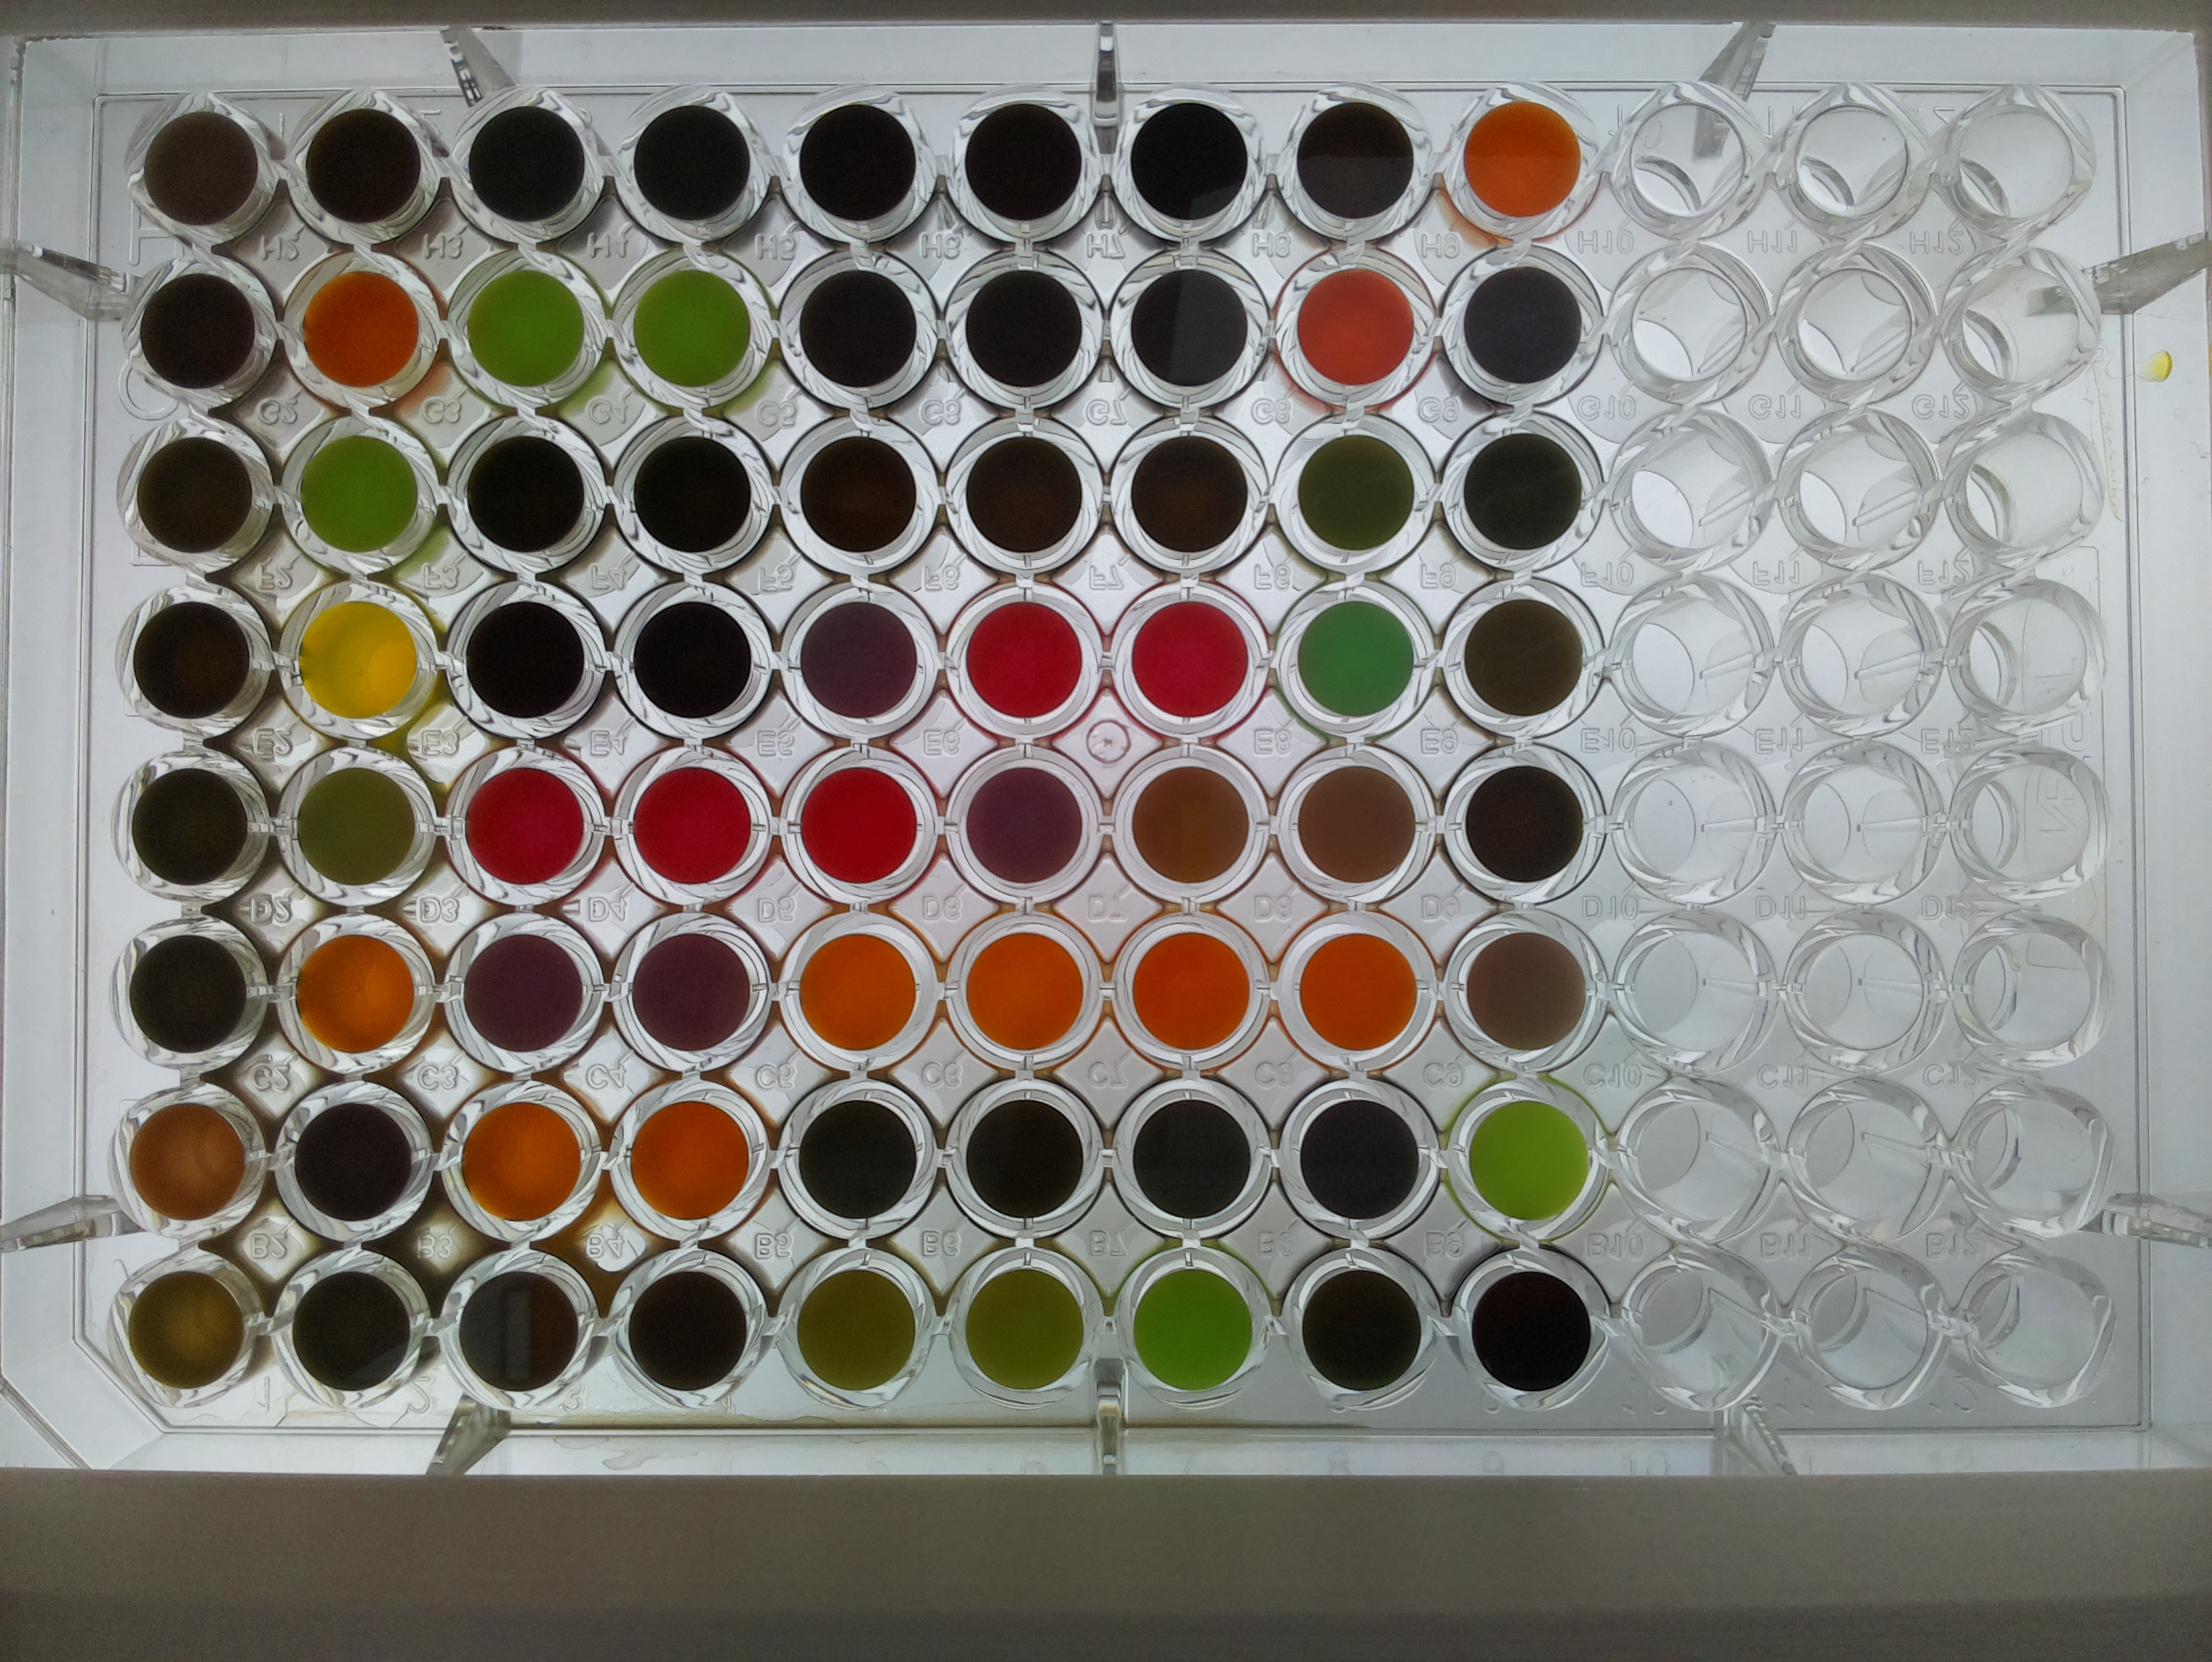

Image captured
Image saved .jpg
None


In [91]:
result = await capture_photo(counter)
print(result)

### Step 4: Extract the new RGB values and update the training data

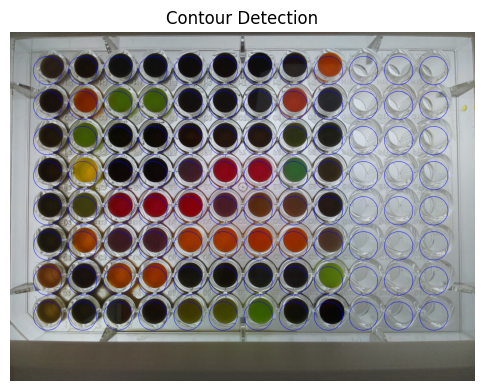

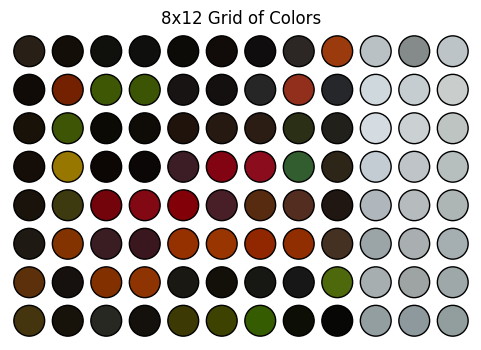

[[185 193 196]
 [207 216 221]
 [212 219 225]
 [195 204 211]
 [175 182 188]
 [155 165 167]
 [166 174 176]
 [147 158 160]] [204.41868799 224.60854837 227.97587592 216.41857591 200.42454939
 191.69246203 193.56910911 190.93978108]


In [92]:
image_path = f'images/{counter}.jpg'
new_rgb_values = image_rgb_extraction(image_path)

fig, ax = plt.subplots(figsize=(6, 4))

# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    new_rgb_values += [[0, 0, 0]] * (rows * cols - len(new_rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = new_rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)


# print(rgb_values)
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()

newest_rgb_values = np.array(new_rgb_values[counter::12])
print(newest_rgb_values,objective(newest_rgb_values))


In [93]:
new_x = next_condition[['volC', 'volM', 'volY', 'volK']].to_numpy()
old__x = train_x[:(counter-1)*8]
new_y = objective(newest_rgb_values).reshape(-1, 1)
old_y = train_y[:(counter-1)*8]

train_x = np.concatenate((old__x, new_x), axis=0)
train_y = np.concatenate((old_y, new_y), axis=0)
print(train_x.shape, train_y.shape)

(72, 4) (72, 1)


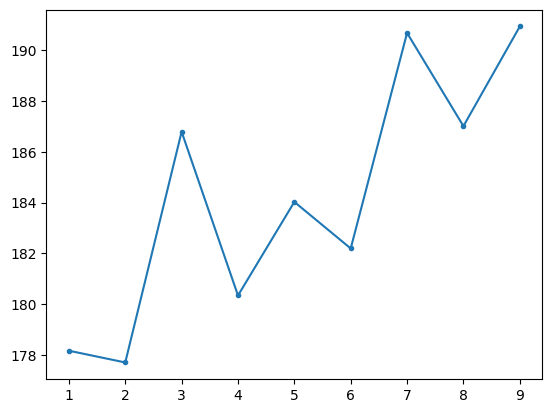

In [94]:
iteration = range(1,counter+1) # 1 is LHS, 2 onward is BO
min_values = [train_y[i:i+8].min() for i in range(0, len(train_y), 8)]
plt.plot(iteration,min_values,'.-')


### Step 5: Iterate! 
- update teh counter and Run Step 1 trought 5 until target reached